# M06-4 | 低位元時 QAT 真的比 PTQ 好嗎：int4 的對照實驗

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m06_qat_pipeline/04_qat_vs_ptq_int4.ipynb)

M06-1 看到 int8 下 PTQ 已經貼著 fp32，QAT 沒有東西可救。這本 notebook 把位元數壓到 **int4**（activation [-8, 7]、weight [-7, 7]），驗證一件聽起來很明顯的事：低位元時 QAT 比 PTQ 有效。

要小心的是，QAT 同時做了兩件事：**多訓練了幾個 epoch**，以及**訓練時模擬量化**。test loss 變低，可能只是因為多訓練了。所以這裡加兩個控制：

- **不給新資料**：QAT 用的 1024 筆，正是 fp32 模型當初訓練用的那一份。
- **對照組「再訓練後 PTQ」**：用同樣的資料、lr、epoch 數再訓練 fp32（不插 fake quant），然後做 PTQ int4。

如果 QAT 的效益只是來自多訓練，對照組也該一樣好。每組跑 5 個 seed（seed 只改變訓練時的資料順序）。

- **A.** 基準：fp32 與 PTQ int4，以及 fp32 模型已經把訓練資料背起來了。
- **B.** QAT int4 vs 再訓練後 PTQ int4。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m06_qat_pipeline")

In [1]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate_loss, make_loader, train, trained_tiny_net
from common.models import example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.qat import INT4_RANGE, freeze_for_eval, qat_quantizer, train_qat
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, MUTED, GRID = "#2a78d6", "#52514e", "#e6e5e1"

## A. 基準

`INT4_RANGE`（`common/qat.py`）就是上面那組整數範圍：XNNPACKQuantizer 的設定函式接受這四個參數，dtype 仍是 int8。
`trained_tiny_net()` 用 `make_loader(n=1024, seed=1)` 這 1024 筆訓練 fp32 模型；下面也算它在這份訓練資料上的 loss：

In [2]:
model = trained_tiny_net()
train_data = make_loader(n=1024, seed=1, shuffle=False)  # fp32 模型的訓練資料，也是 QAT 要用的那一份
test_loader = make_loader(n=1024, seed=2, shuffle=False)


def ptq_int4(m):
    prepared = prepare_pt2e(export_module(copy.deepcopy(m), example_inputs()),
                            get_xnnpack_quantizer(is_per_channel=True, **INT4_RANGE)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return convert_pt2e(prepared)


ptq = ptq_int4(model)
FP32_LOSS, PTQ_LOSS = evaluate_loss(model, test_loader), evaluate_loss(ptq, test_loader)
table([["fp32", f"{evaluate_loss(model, train_data):.3f}", f"{FP32_LOSS:.3f}"],
       ["PTQ int4", f"{evaluate_loss(ptq, train_data):.3f}", f"{PTQ_LOSS:.3f}"]],
      ["模型", "訓練資料上的 loss", "test loss"])

模型,訓練資料上的 loss,test loss
fp32,0.006,0.826
PTQ int4,0.053,1.071


In [3]:
assert evaluate_loss(model, train_data) < 0.05 and PTQ_LOSS > FP32_LOSS + 0.1

- fp32 模型在訓練資料上的 loss 幾乎是 0，test loss 卻有 0.8 左右：它已經把這 1024 筆背起來了。再用同一份資料訓練，不會帶來新的資訊。
- PTQ int4 的 test loss 比 fp32 高一截，這是 QAT 要追回來的部分。

## B. QAT int4 vs 再訓練後 PTQ int4

兩組用同樣的配方：同一份 1024 筆、lr 1e-3、5 個 epoch、同一組 seed。

- **QAT int4**：`prepare_qat_pt2e` 之後用 `train_qat()` 訓練（M06-1 的迴圈），`freeze_for_eval()` 之後評估。評估用 fake quant 圖、不 convert：M06-3 已確認兩者輸出相同。
- **再訓練後 PTQ int4**：fp32 模型用 `common.data.train()`（一般的 PyTorch 訓練迴圈）再訓練，然後做 PTQ int4。順便記下再訓練後的 fp32 本身。

In [4]:
SEEDS = (1, 2, 3, 4, 5)
base = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True), qat_quantizer(bits=4))

results = {"QAT int4": [], "再訓練後 PTQ int4": [], "再訓練後的 fp32": []}
for seed in SEEDS:
    qat = freeze_for_eval(train_qat(copy.deepcopy(base), epochs=5, lr=1e-3, seed=seed))
    results["QAT int4"].append(evaluate_loss(qat, test_loader))

    retrained = copy.deepcopy(model).train()
    torch.manual_seed(seed)  # 和 train_qat 一樣：seed 決定資料的 shuffle 順序
    train(retrained, make_loader(n=1024, seed=1), epochs=5, lr=1e-3)
    retrained.eval()
    results["再訓練後的 fp32"].append(evaluate_loss(retrained, test_loader))
    results["再訓練後 PTQ int4"].append(evaluate_loss(ptq_int4(retrained), test_loader))

圖的每一個 row 是一組：淺色點是各 seed 的 test loss，深色短線是 5 個 seed 的平均。點線是 fp32，虛線是 PTQ int4，越左越好。

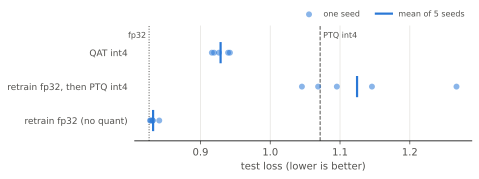

In [5]:
#| code-fold: true
#| code-summary: 畫圖的程式
LABELS = {"QAT int4": "QAT int4", "再訓練後 PTQ int4": "retrain fp32, then PTQ int4", "再訓練後的 fp32": "retrain fp32 (no quant)"}
fig, ax = plt.subplots(figsize=(6.8, 2.6))
for i, (name, vals) in enumerate(results.items()):
    ax.scatter(vals, [i] * len(vals), s=36, color=BLUE, alpha=0.55, linewidths=0,
               label="one seed" if i == 0 else None, zorder=3)
    m = sum(vals) / len(vals)
    ax.plot([m, m], [i - 0.28, i + 0.28], color=BLUE, lw=2.2, label="mean of 5 seeds" if i == 0 else None, zorder=3)
for value, name, style, dx, ha in ((FP32_LOSS, "fp32", ":", -3, "right"), (PTQ_LOSS, "PTQ int4", "--", 3, "left")):
    ax.axvline(value, color=MUTED, lw=1, ls=style)
    ax.annotate(name, (value, -0.5), xytext=(dx, 0), textcoords="offset points", ha=ha, va="center", color=MUTED, fontsize=8)
ax.set_yticks(range(len(results)), [LABELS[n] for n in results], fontsize=9)
ax.set_ylim(len(results) - 0.4, -0.8)
ax.set_xlabel("test loss (lower is better)", color=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, left=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False, labelcolor=MUTED, fontsize=8)
fig.tight_layout()
plt.show()

In [6]:
table([[name, f"{sum(v) / len(v):.3f}", f"{min(v):.3f} ~ {max(v):.3f}"] for name, v in results.items()] +
      [["（參考）原本的 fp32", f"{FP32_LOSS:.3f}", "—"], ["（參考）原本的 PTQ int4", f"{PTQ_LOSS:.3f}", "—"]],
      ["組別", "test loss 平均", "min ~ max（5 個 seed）"])

組別,test loss 平均,min ~ max（5 個 seed）
QAT int4,0.929,0.916 ~ 0.942
再訓練後 PTQ int4,1.124,1.045 ~ 1.267
再訓練後的 fp32,0.832,0.828 ~ 0.841
（參考）原本的 fp32,0.826,—
（參考）原本的 PTQ int4,1.071,—


In [7]:
qat, re_ptq, re_fp32 = results["QAT int4"], results["再訓練後 PTQ int4"], results["再訓練後的 fp32"]
wins = sum(q < PTQ_LOSS for q in qat)
print(f"QAT int4 贏過 PTQ int4 的 seed：{wins} / {len(SEEDS)}")
assert sum(qat) / len(qat) < PTQ_LOSS and max(qat) < min(re_ptq)  # QAT 的平均優於 PTQ，而且每個 seed 都優於對照組
assert all(abs(v - FP32_LOSS) < 0.05 for v in re_fp32)  # 再訓練本身幾乎不改變 fp32

QAT int4 贏過 PTQ int4 的 seed：5 / 5


- **QAT int4 明顯優於 PTQ int4**：平均 test loss 低一大截，這是 QAT 的主要效益。
- **效益來自量化適應，不是多訓練**：用同樣的資料、同樣的配方再訓練 fp32，fp32 本身幾乎不變（訓練資料早就背起來了），之後做 PTQ int4 也沒有比原本的 PTQ 好。同樣是多訓練 5 個 epoch，只有訓練時模擬量化的那一組追回了精度。
- **seed 間有波動**：seed 只改變資料的順序，QAT 的 test loss 就有一段範圍；這次上面印出的 seed 都贏過 PTQ，但不能保證每次訓練都贏，比較時要跑多個 seed、看平均。再訓練後 PTQ 那組的波動更大：PTQ 對 weight 的小變動很敏感。

## 小結

- int4 下 QAT 的平均 test loss 明顯優於 PTQ。
- QAT 用的是 fp32 模型已經背起來的同一份資料；同樣配方再訓練 fp32 後做 PTQ 沒有改善，所以效益來自訓練時模擬量化，不是新資料或多訓練。